# 1D estacionario en diferencias finitas

Mismo modelo de Kozono & Koyaguchi (2009) que `RIconduitex5_5_f`, marchado en $z$ con RK4. **No usa `scikits.odes` / IDA.**

- **Pre-fragmentación:** HEM + ecuación de estado ($u_m = u_g$).
- **Post-fragmentación:** las mismas ecuaciones bifásicas de Kozono que usa IDA (`n_eq = 4`): $\varphi$ es independiente, $u_g$ se separa de $u_m$.
- **Tiro** sobre $v_\mathrm{inicial}$ (boca sónica o $P \approx P_\mathrm{atm}$).

Parámetros: Calbuco 2015 (`calbuco2015d.py`). Ejecutar todas las celdas.

In [1]:
%matplotlib inline
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.getcwd())

from calbuco2015d import (
    H, Patm, T1, geometry, h2o1, overP1, phicrit, radius1, xi1,
)
from RIconduit1D_FD import RIconduit1D_FD_f

print("Parámetros Calbuco 2015")
print(f"  radio        = {radius1} m")
print(f"  sobrepresión = {overP1/1e6:.1f} MPa")
print(f"  H2O          = {h2o1} wt%")
print(f"  T            = {T1-273.15:.0f} °C")
print(f"  xi           = {xi1}")
print(f"  H            = {H/1e3:.1f} km")
print(f"  φ_crit input = {phicrit}")
print(f"  geometría    = {geometry}")

Parámetros Calbuco 2015
  radio        = 16 m
  sobrepresión = 5.0 MPa
  H2O          = 4 wt%
  T            = 970 °C
  xi           = 0.25
  H            = -7.0 km
  φ_crit input = 0.8
  geometría    = cylinder


## Tiro + marcha en $z$

`RIconduit1D_FD_f` devuelve la misma tupla que `RIconduitex5_5_f`. Equivale a llamar `RIconduitex5_5_f(...)` (el default ya es diferencias finitas).

In [2]:
(
    zsol, sol, count, vinicial, rho_m, rbub, visc,
    rho_ti, fragcrit, phicrit_run, limphi1, limphi2, co, xi, xfinal, cg,
) = RIconduit1D_FD_f(radius1, overP1, h2o1, T1, xi1)


Count = 1 
Initial velocity = 10.0 

Velocidad de salida: 46.30840309174566 
Presión de salida: 11518168.458929587 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.6993798032874333
vmax: 50.0 
vmin: 10.0

Count = 2 
Initial velocity = 30.0 



Velocidad de salida: 1064.5594848507096 
Presión de salida: 1560500.3518691459 
Profundidad de salida: -1161.1729692482409 
Contenido de burbujas de salida: 0.8936115392985848
vmax: 30.0 
vmin: 10.0

Count = 3 
Initial velocity = 20.0 



Velocidad de salida: 1031.4657192814213 
Presión de salida: 1068319.5471745313 
Profundidad de salida: -182.21121352484874 
Contenido de burbujas de salida: 0.9201287377371656
vmax: 20.0 
vmin: 10.0

Count = 4 
Initial velocity = 15.0 



Velocidad de salida: 93.03458967092932 
Presión de salida: 8317037.358609634 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.7796791393791292
vmax: 20.0 
vmin: 15.0

Count = 5 
Initial velocity = 17.5 



Velocidad de salida: 140.01214197349074 
Presión de salida: 6376727.322402874 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.8283934553795778
vmax: 20.0 
vmin: 17.5

Count = 6 
Initial velocity = 18.75 



Velocidad de salida: 1100.2759838272377 
Presión de salida: 940901.1853020284 
Profundidad de salida: -26.509888572804584 
Contenido de burbujas de salida: 0.9246549491133862
vmax: 18.75 
vmin: 17.5

Count = 7 
Initial velocity = 18.125 



... (6 outputs left out)

Velocidad de salida: 1034.447606927214 
Presión de salida: 987223.8642683753 
Profundidad de salida: -0.08570486031430846 
Contenido de burbujas de salida: 0.9246905008310202
vmax: 18.544921875 
vmin: 18.53515625

Count = 14 
Initial velocity = 18.5400390625 



Velocidad de salida: 482.56038549668506 
Presión de salida: 2042983.340342119 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.911502224816682
vmax: 18.544921875 
vmin: 18.5400390625

Count = 15 
Initial velocity = 18.54248046875 



Velocidad de salida: 615.8607676427744 
Presión de salida: 1620219.4647006064 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.9170675668472063
vmax: 18.544921875 
vmin: 18.54248046875

Count = 16 
Initial velocity = 18.543701171875 



Velocidad de salida: 777.3136377467797 
Presión de salida: 1297639.6429001756 
Profundidad de salida: 0.0 
Contenido de burbujas de salida: 0.9211030035166334
>>> Solucion de tiro convergida.


In [3]:
P, phi, Nd, x_cr, um, ug = (sol[:, i] for i in range(6))
z_km = zsol / 1e3

if geometry == "dyke":
    from calbuco2015d import dl
    Q = vinicial * radius1 * dl
else:
    Q = vinicial * np.pi * radius1 ** 2

frag = np.where(phi >= phicrit_run)[0]
z_frag = zsol[frag[0]] if frag.size else np.nan

print("Resumen")
print(f"  tiros          = {count}")
print(f"  vinicial       = {vinicial:.4f} m/s")
print(f"  Q              = {Q*rho_ti:.3g} kg/s")
print(f"  z_boca         = {zsol[-1]:.2f} m")
print(f"  P_boca         = {P[-1]/1e5:.3f} bar   (P_atm = {Patm/1e5:.3f} bar)")
print(f"  φ_boca         = {phi[-1]:.4f}")
print(f"  um, ug boca    = {um[-1]:.2f}, {ug[-1]:.2f} m/s")
print(f"  φ_crit (Ca)    = {phicrit_run:.3f}")
print(f"  lim φ perm.    = [{limphi1:.3f}, {limphi2:.3f}]")
if frag.size:
    print(f"  fragmentación  = {z_frag/1e3:.2f} km  ({frag.size} nodos)")
else:
    print("  fragmentación  = no alcanzada")

Resumen
  tiros          = 16
  vinicial       = 18.5437 m/s
  Q              = 3.67e+07 kg/s
  z_boca         = 0.00 m
  P_boca         = 12.976 bar   (P_atm = 1.013 bar)
  φ_boca         = 0.9211
  um, ug boca    = 226.70, 777.31 m/s
  φ_crit (Ca)    = 0.580
  lim φ perm.    = [0.347, 0.357]
  fragmentación  = -1.30 km  (661 nodos)


## Perfiles a lo largo del conducto

Misma disposición de seis paneles que `mainconduit5_5.ipynb`.

<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_7634/2172570608.py:32: SyntaxWarning: invalid escape sequence '\m'
  f"1D FD — Calbuco    $v_\mathrm{{in}}$ = {vinicial:.2f} m/s",


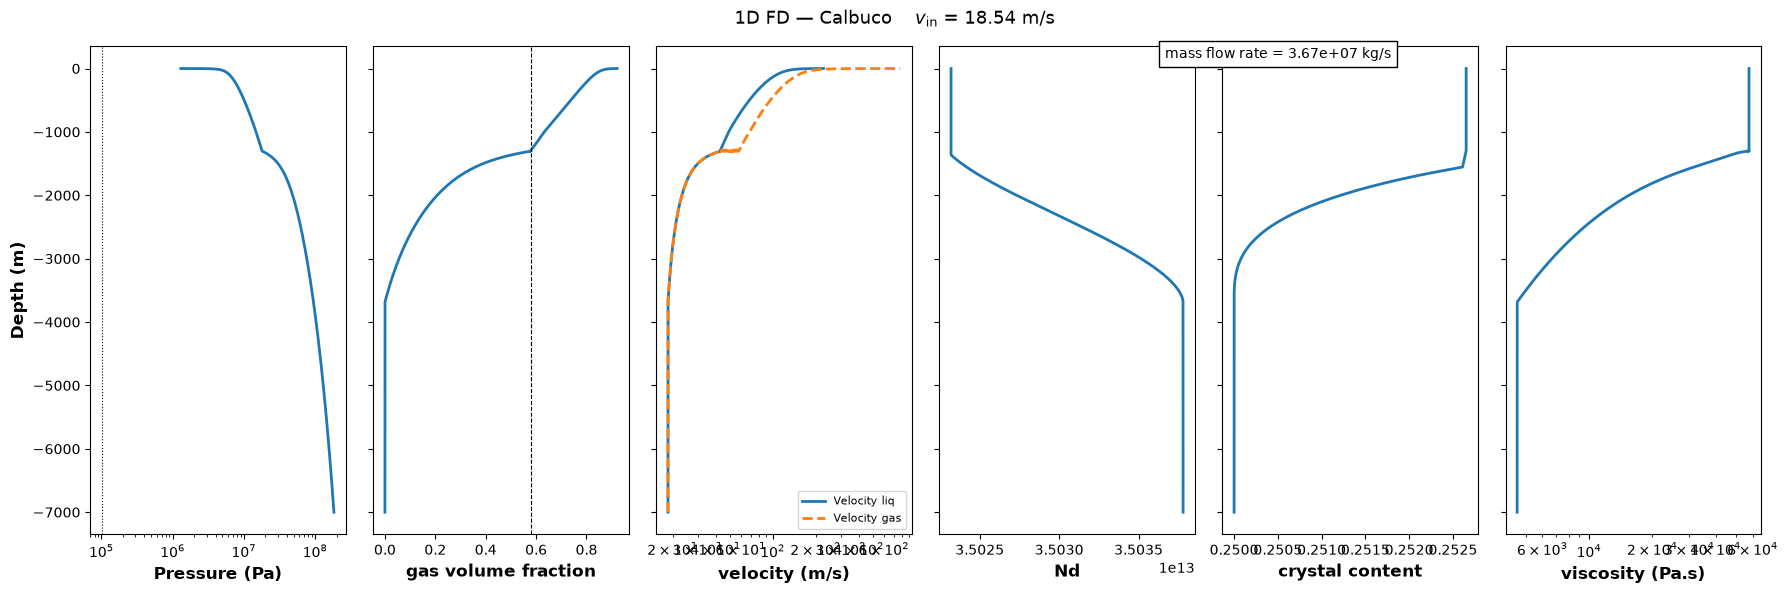

In [4]:
fig, axs = plt.subplots(1, 6, figsize=(18, 6), sharey=True)

axs[0].semilogx(P, zsol, linewidth=2)
axs[0].axvline(Patm, color="k", ls=":", lw=0.8)
axs[0].set_xlabel("Pressure (Pa)", fontweight="bold", fontsize=12)
axs[0].set_ylabel("Depth (m)", fontweight="bold", fontsize=12)

axs[1].plot(phi, zsol, linewidth=2)
axs[1].axvline(phicrit_run, color="k", ls="--", lw=0.8)
axs[1].set_xlabel("gas volume fraction", fontweight="bold", fontsize=12)

axs[2].semilogx(um, zsol, label="Velocity liq", linewidth=2)
axs[2].semilogx(ug, zsol, "--", label="Velocity gas", linewidth=2)
axs[2].set_xlabel("velocity (m/s)", fontweight="bold", fontsize=12)
axs[2].legend(fontsize=8)

axs[3].plot(Nd, zsol, linewidth=2)
axs[3].set_xlabel("Nd", fontweight="bold", fontsize=12)

axs[4].plot(x_cr, zsol, linewidth=2)
axs[4].set_xlabel("crystal content", fontweight="bold", fontsize=12)

axs[5].semilogx(visc, zsol, linewidth=2)
axs[5].set_xlabel("viscosity (Pa.s)", fontweight="bold", fontsize=12)

fig.text(
    0.65, 0.90,
    f"mass flow rate = {Q * rho_ti:.3g} kg/s",
    bbox=dict(facecolor="white", edgecolor="black"),
)
fig.suptitle(
    f"1D FD — Calbuco    $v_\mathrm{{in}}$ = {vinicial:.2f} m/s",
    fontsize=13,
)
fig.tight_layout()
plt.show()

Presión, $\varphi$ y velocidades con profundidad en km. Después de fragmentar, $u_g$ (punteada) se separa de $u_m$: es el mismo postproceso que IDA (`n = (c_0 - C_1 P^\beta)/(1-C_1 P^\beta)`).

<>:27: SyntaxWarning: invalid escape sequence '\m'
<>:27: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_7634/2597129338.py:27: SyntaxWarning: invalid escape sequence '\m'
  fig.suptitle(f"1D estacionario FD — Calbuco   $v_\mathrm{{in}} = {vinicial:.2f}$ m/s")


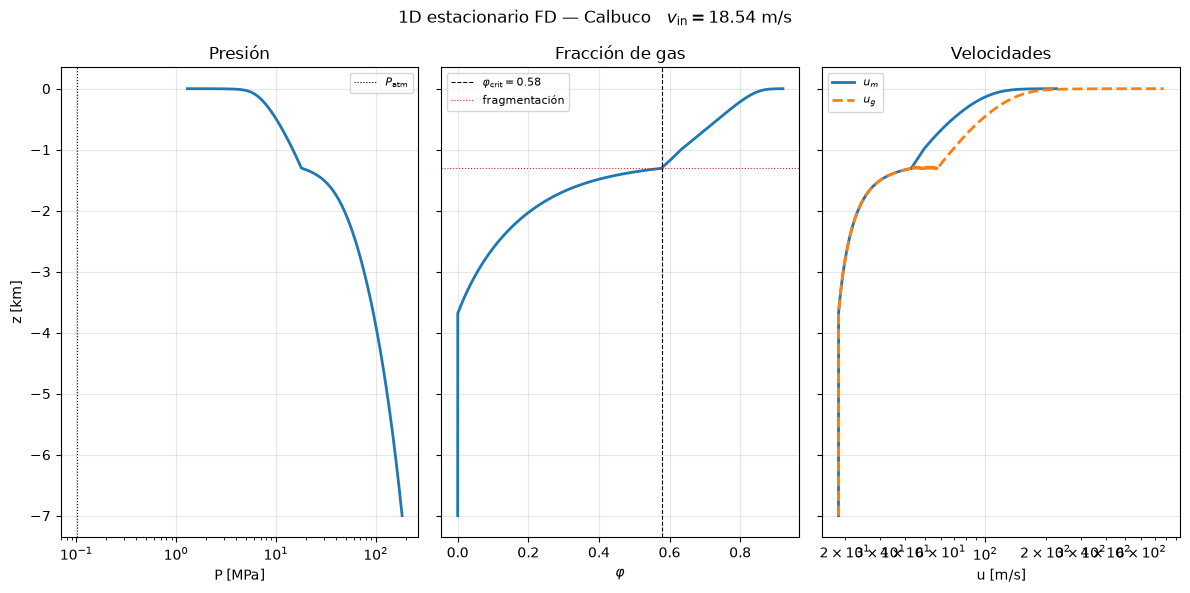

Figura: RIconduit1D_FD_calbuco.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)

axes[0].semilogx(P / 1e6, z_km, linewidth=2)
axes[0].axvline(Patm / 1e6, color="k", ls=":", lw=0.8, label=r"$P_\mathrm{atm}$")
axes[0].set_xlabel("P [MPa]")
axes[0].set_ylabel("z [km]")
axes[0].set_title("Presión")
axes[0].legend(fontsize=8)

axes[1].plot(phi, z_km, linewidth=2)
axes[1].axvline(phicrit_run, color="k", ls="--", lw=0.8, label=fr"$\varphi_\mathrm{{crit}} = {phicrit_run:.2f}$")
if frag.size:
    axes[1].axhline(z_frag / 1e3, color="C3", ls=":", lw=0.8, label="fragmentación")
axes[1].set_xlabel(r"$\varphi$")
axes[1].set_title("Fracción de gas")
axes[1].legend(fontsize=8)

axes[2].semilogx(um, z_km, linewidth=2, label=r"$u_m$")
axes[2].semilogx(ug, z_km, "--", linewidth=2, label=r"$u_g$")
axes[2].set_xlabel("u [m/s]")
axes[2].set_title("Velocidades")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.suptitle(f"1D estacionario FD — Calbuco   $v_\mathrm{{in}} = {vinicial:.2f}$ m/s")
fig.tight_layout()
plt.savefig("RIconduit1D_FD_calbuco.png", dpi=140, bbox_inches="tight")
plt.show()
print("Figura: RIconduit1D_FD_calbuco.png")